In [1]:
import sys 
sys.path.append("../")

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from src.config import PROCESSED_DATA_PATH, MODEL_PATH , REPORTS_DIR

### Prepare data and model loading

In [4]:
df = pd.read_csv(PROCESSED_DATA_PATH)

X = df.drop(columns=["Loan_Status"])
y = df["Loan_Status"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

best_model = joblib.load(MODEL_PATH)
print("Saved model loaded successfully.")

Saved model loaded successfully.


### Model predictions

In [ ]:
y_pred = best_model.predict(X_test)

### Evaluation metrics

In [6]:
metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision_macro": precision_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "recall_macro": recall_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "f1_macro": f1_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "precision_weighted": precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    ),
    "recall_weighted": recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    ),
    "f1_weighted": f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    ),
}

metrics_df = pd.DataFrame(
    metrics.items(),
    columns=["metric", "value"],
)

display(metrics_df.round(4))

,metric,value
0,accuracy,0.8537
1,precision_macro,0.8931
2,recall_macro,0.7704
3,f1_macro,0.8016
4,precision_weighted,0.8696
5,recall_weighted,0.8537
6,f1_weighted,0.8404


### Classification report

In [ ]:
report_dict = classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Rejected", "Approved"],
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(report_dict).T

display(report_df.round(4))

# report_df.to_csv(
#     REPORTS_DIR / "classification_report.csv",
#     index=True,
#     index_label="class_or_metric",
# )

,precision,recall,f1-score,support
Rejected,0.9545,0.5526,0.7000,38.0000
Approved,0.8317,0.9882,0.9032,85.0000
accuracy,0.8537,0.8537,0.8537,0.8537
macro avg,0.8931,0.7704,0.8016,123.0000
weighted avg,0.8696,0.8537,0.8404,123.0000


### Confusion matrix

In [8]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1],
)

cm_df = pd.DataFrame(
    cm,
    index=["Actual Rejected", "Actual Approved"],
    columns=["Predicted Rejected", "Predicted Approved"],
)

display(cm_df)

# save confusion matrix to CSV
# cm_df.to_csv( REPORTS_DIR / "confusion_matrix.csv", index=True)

,Predicted Rejected,Predicted Approved
Actual Rejected,21,17
Actual Approved,1,84


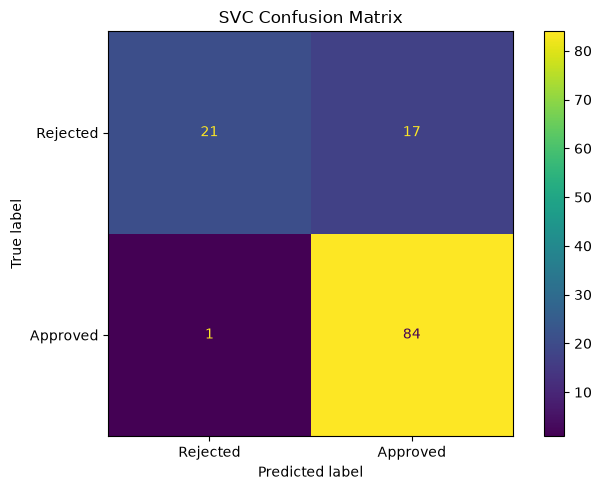

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Rejected", "Approved"],
).plot(
    ax=ax,
    values_format="d",
)

ax.set_title("SVC Confusion Matrix")
plt.tight_layout()

# fig.savefig(
#     REPORTS_DIR / "confusion_matrix.png",
#     dpi=300,
#     bbox_inches="tight",
# )

plt.show()